# <center> NGC3184 - Morphological Classification

---

## FITS File

<img src='https://hst-docs.stsci.edu/hstdhb/files/60243022/60243024/1/1560629126446/fig31_fitsformat.png'>

## Morphology Classification

<img src='https://upload.wikimedia.org/wikipedia/commons/thumb/8/85/Hubble_-_de_Vaucouleurs_Galaxy_Morphology_Diagram.png/1920px-Hubble_-_de_Vaucouleurs_Galaxy_Morphology_Diagram.png'>

### Step 1: Dataset Access for NGC3184
* You have two links given to you which contains FITS files:-
  * Link 1:- https://drive.google.com/uc?id=1I2paRfotJoNPLYvP_YbWAxblaEFVYfge
  * Link 2:- https://drive.google.com/uc?id=1ExKsAfzowP5TbhyTDwUMgzyNtV1flgNU

* Create two different variables `url_1` and `url_2` and save the respective links in the same order as given.


In [1]:
# Assign fits paths to respective variables
url_1 = 'https://drive.google.com/uc?id=1I2paRfotJoNPLYvP_YbWAxblaEFVYfge' # path to link 1
url_2 = 'https://drive.google.com/uc?id=1ExKsAfzowP5TbhyTDwUMgzyNtV1flgNU' # path to link 2

### Step 2: Explore the FITS files

* Read each of the FITS file.
* Get the summary information of each.
* Understand the header information and understand which FITS file is for `r-band` and which one is for `g-band`.
* Figure out which of the data units for each FITS file is good to continue with the image processing.

In [2]:
from astropy.io import fits

In [7]:
# Read all the fits files
url_1_fits = fits.open(url_1)
url_2_fits = fits.open(url_2)

In [11]:
# Get the Summary Information of these fits files
url_1_fits.info()
print('-------')
url_2_fits.info()

Filename: /root/.astropy/cache/download/url/b70ff66a3a25e6a085808deaa45226bc/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     137   (300, 300)   float32   
-------
Filename: /root/.astropy/cache/download/url/fcc7340eb16bddd1671b4ee54a1c8319/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     137   (300, 300)   float32   


In [15]:
# Explore the header information here to identify the band type wrt fits file
url_1_header = url_1_fits[0].header
url_2_header = url_2_fits[0].header

In [20]:
url_1_header # r band

SIMPLE  =                    T / Written by SkyView Thu Dec 12 09:32:09 EST 2024
BITPIX  =                  -32 / 4 byte floating point                          
NAXIS   =                    2 / Two dimensional image                          
NAXIS1  =                  300 / Width of image                                 
NAXIS2  =                  300 / Height of image                                
CRVAL1  =           154.570771 / Reference longitude                            
CRVAL2  =            41.424381 / Reference latitude                             
RADESYS = 'FK5     '           / Coordinate system                              
EQUINOX =               2000.0 / Epoch of the equinox                           
CTYPE1  = 'RA---TAN'           / Coordinates -- projection                      
CTYPE2  = 'DEC--TAN'           / Coordinates -- projection                      
CRPIX1  =                150.5 / X reference pixel                              
CRPIX2  =                150

In [23]:
url_2_header   # g band

SIMPLE  =                    T / Written by SkyView Thu Dec 12 09:32:02 EST 2024
BITPIX  =                  -32 / 4 byte floating point                          
NAXIS   =                    2 / Two dimensional image                          
NAXIS1  =                  300 / Width of image                                 
NAXIS2  =                  300 / Height of image                                
CRVAL1  =           154.570771 / Reference longitude                            
CRVAL2  =            41.424381 / Reference latitude                             
RADESYS = 'FK5     '           / Coordinate system                              
EQUINOX =               2000.0 / Epoch of the equinox                           
CTYPE1  = 'RA---TAN'           / Coordinates -- projection                      
CTYPE2  = 'DEC--TAN'           / Coordinates -- projection                      
CRPIX1  =                150.5 / X reference pixel                              
CRPIX2  =                150

In [18]:
# Complete this code cell
print('url_1 or link 1 is for:- r-band') # relpace x with r or g
print('url_2 or link 2 is for:- g-band') # replace y with r or g

url_1 or link 1 is for:- r-band
url_2 or link 2 is for:- g-band


In [25]:
# Explore the data units of the fits files and decide which data unit per fits file to be used for image processing
url_1_data = url_1_fits[0].data
url_2_data = url_2_fits[0].data

In [50]:
import matplotlib.pyplot as plt
import numpy as np

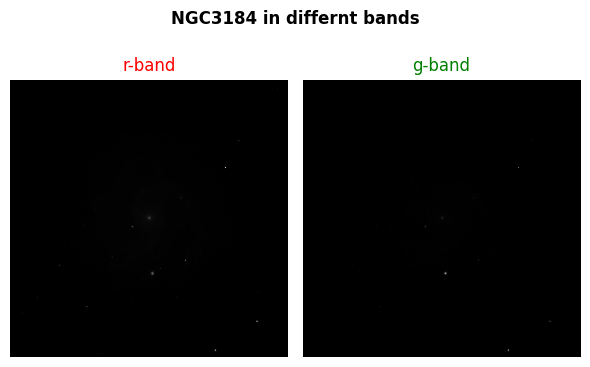

In [49]:
# Visualize r band and g band images for NGC3184 using subplot
plt.figure(figsize=(6, 4))
plt.suptitle('NGC3184 in differnt bands', weight='bold')
plt.subplot(1, 2, 1)
plt.imshow(url_1_data, cmap='gray')
plt.title('r-band', color='r')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(url_2_data, cmap='gray')
plt.title('g-band', color='g')
plt.axis('off')
plt.tight_layout()
plt.show()

### Step 3: Wide Scale and Nucleus Scale

* Here, you will figure out the cropping for wide and nucleus scale.
* This is done to plot side by side comparison later on in this notebook.
* Main task is to figure out the amount of cropping to be implemented for wide and nucleus scale.

In [70]:
# Figure out the cropping by inspecting the data unit selected from the previous step

# Wide Scale
w_rband = url_1_data[40:260, 20:265]
w_gband = url_2_data[40:260, 20:265]


# Nucleus Scale
n_rband = url_1_data[90:200, 80:200]
n_gband = url_2_data[90:200, 80:200]

In [73]:
from matplotlib.colors import LogNorm

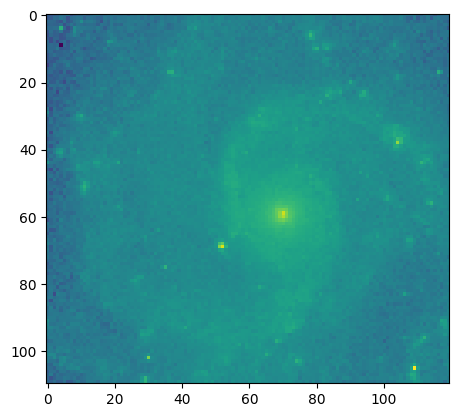

In [77]:
plt.imshow(n_rband, norm=LogNorm())

### Step 4: Getting insights from the Data Units

* Implement **Sato** filter on red data unit (on both wide and nucleus scale).
* Implement **Meijering** filter on green data unit (on both wide and nucleus scale).
* Use the spectral list given below to visualize red and green data units to decode NGC3184.

In [84]:
# Spectral list to be used in a for loop
SPECTRAL_LIST = ["gray","jet","hot","prism","nipy_spectral",
             "gist_ncar","gist_earth","gist_stern","flag","gnuplot2","afmhot",
            "bwr",'PiYG','PRGn','BrBG','PuOr','RdGy','RdBu','terrain']

In [78]:
from skimage.filters import sato, meijering

In [82]:
# Implement Sato on Wide Scale and Nucleus Scale for Red Data Unit
sato_w_rband = sato(w_rband)
sato_n_rband = sato(n_rband)

# Implement Meijering on Wide Scale and Nucleus Scale for Green Data Unit
mei_w_gband = meijering(w_gband)
mei_n_gband = meijering(n_gband)

In [91]:
# Create a function to plot the effect of filters on given data unit input
def plotting_NGC3184(data_unit, spectral_list):
  """
  Side by side plots of wide scale and nucleus scale on different colormaps

  Parameters
  ----------
  data_unit (tuple): Tuple of wide scale and nucleus scale of the data unit to plot
  spectral_list (list): List of different colormaps to use in the plotting

  Should use subplot in a for loop to visualize comparison in all the colormaps in the specral_list
  """
  for color_map in spectral_list:
    plt.figure(figsize=(6, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(data_unit[0], cmap=color_map)
    plt.title(f'Wide Scale - {color_map}')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(data_unit[1], cmap=color_map)
    plt.title(f'Nucleus Scale - {color_map}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

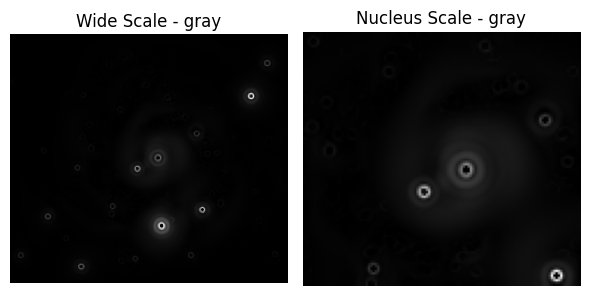

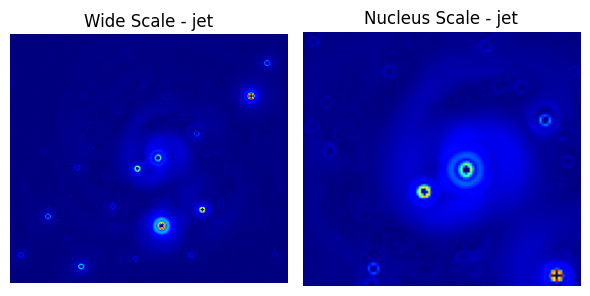

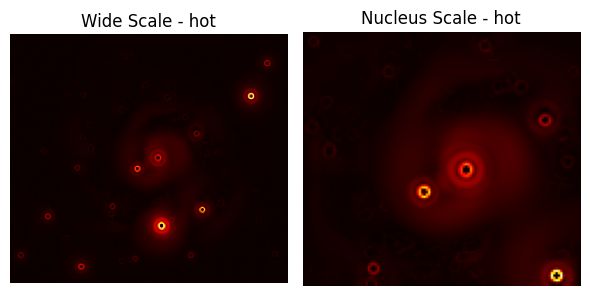

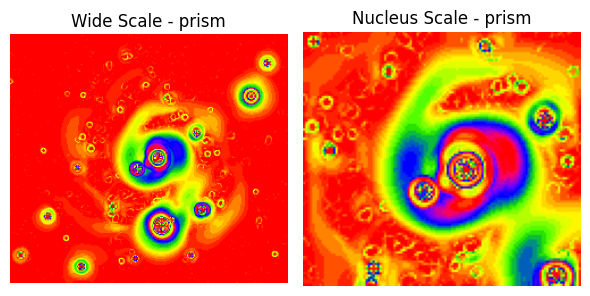

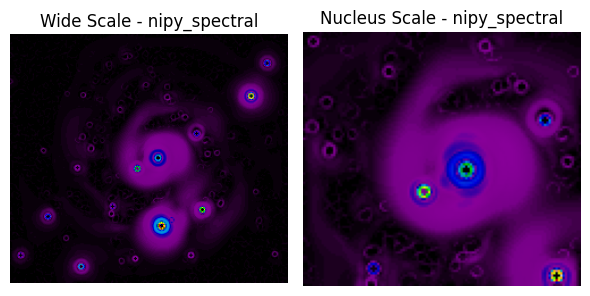

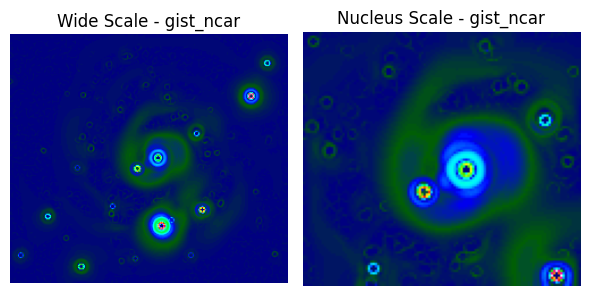

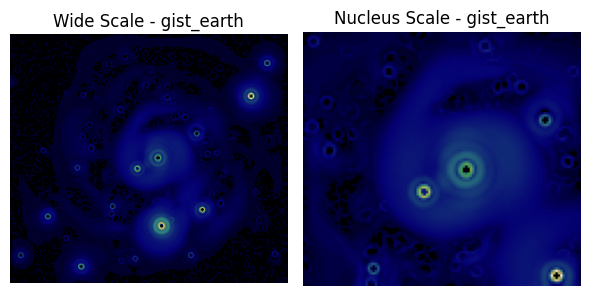

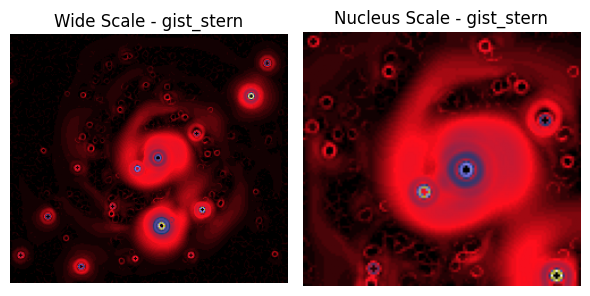

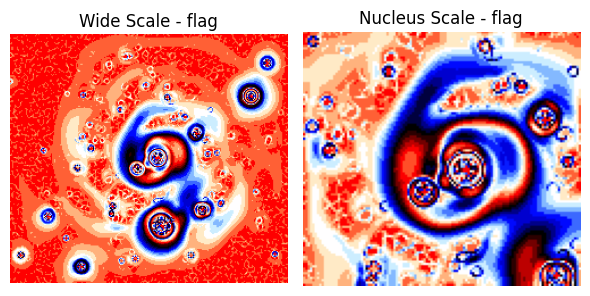

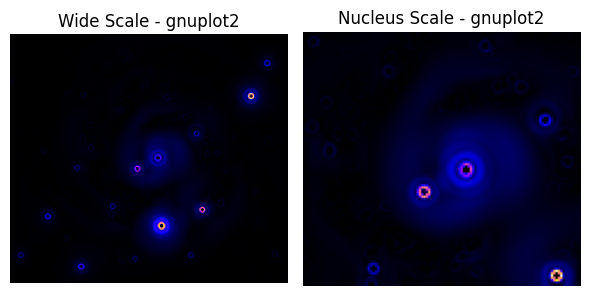

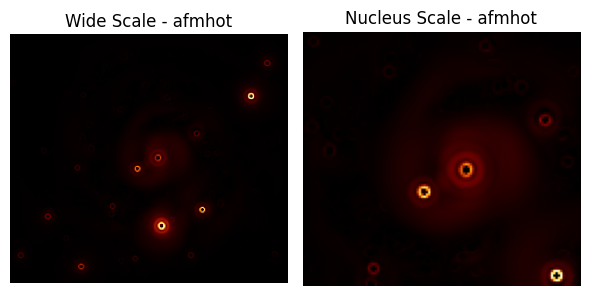

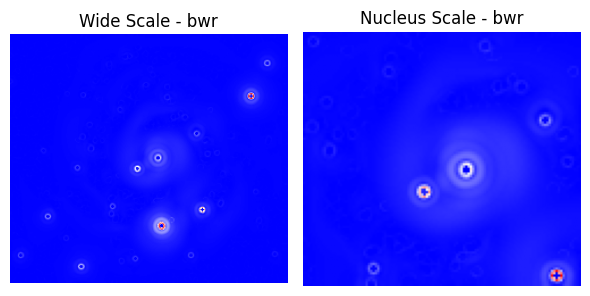

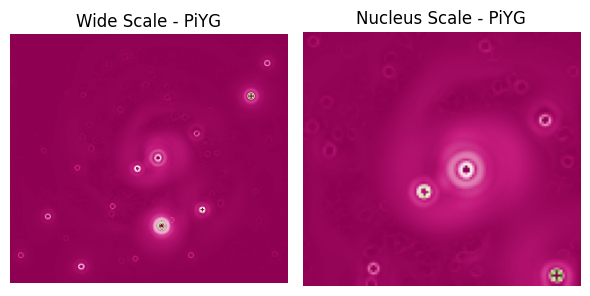

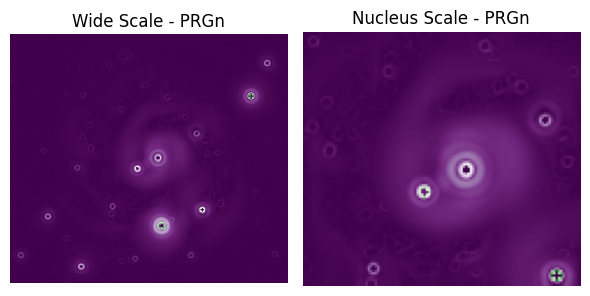

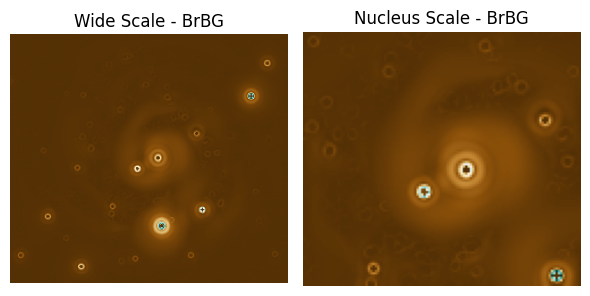

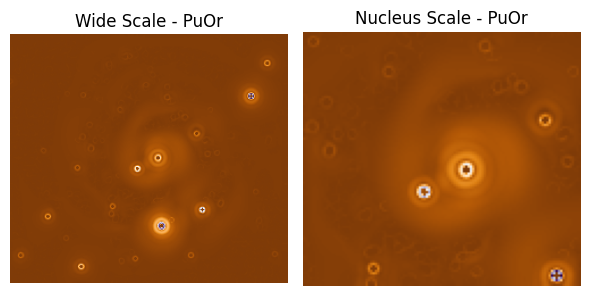

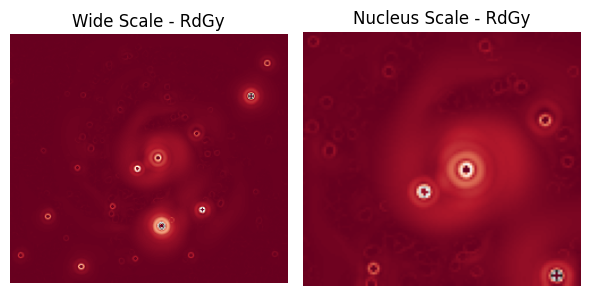

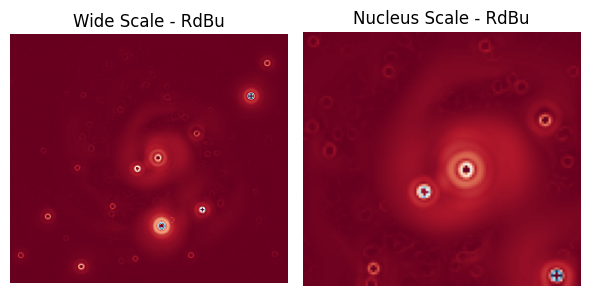

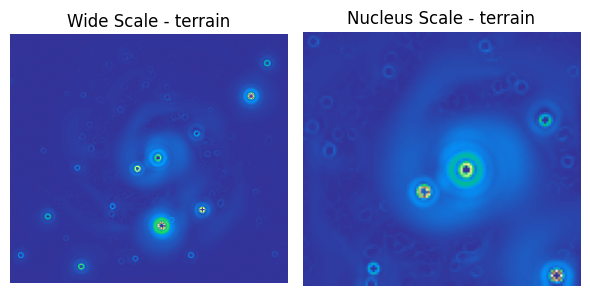

In [92]:
# Use the plotting_NGC3184 to plot red data unit (with sato filter)
plotting_NGC3184((sato_w_rband, sato_n_rband), SPECTRAL_LIST)

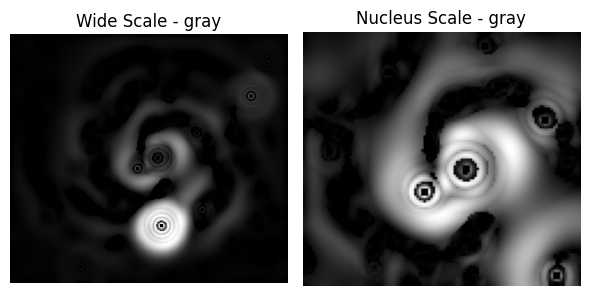

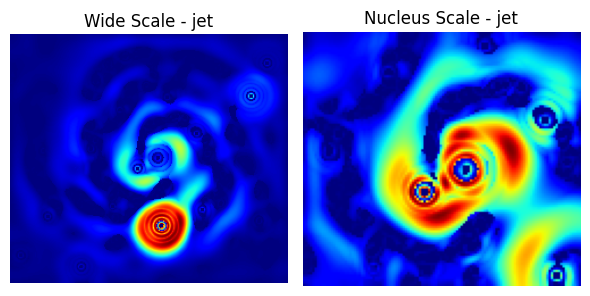

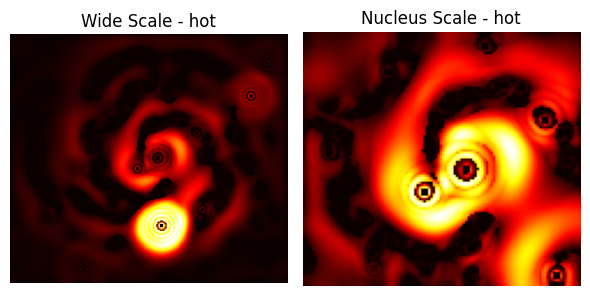

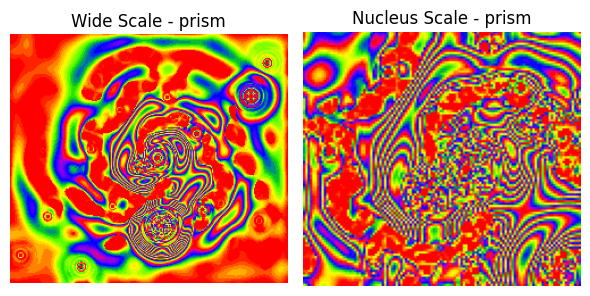

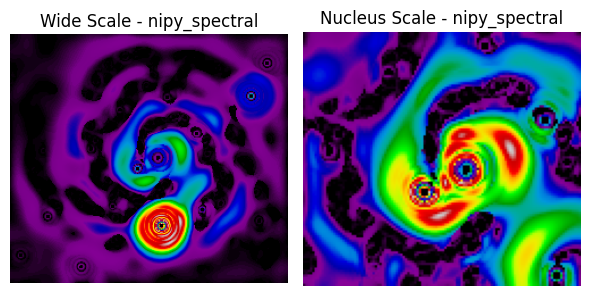

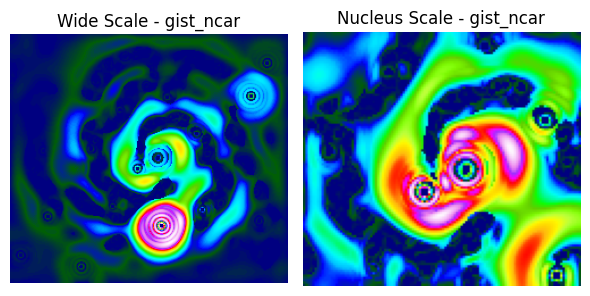

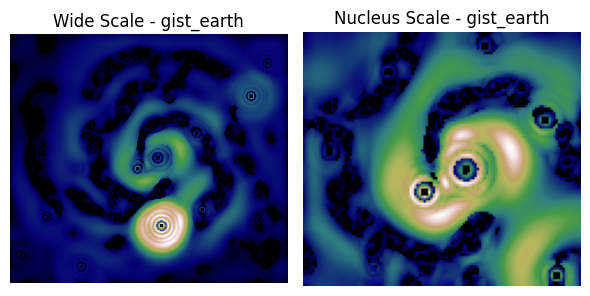

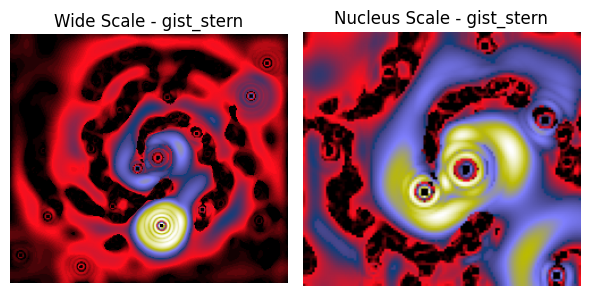

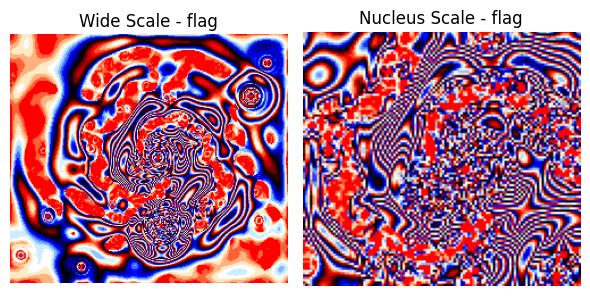

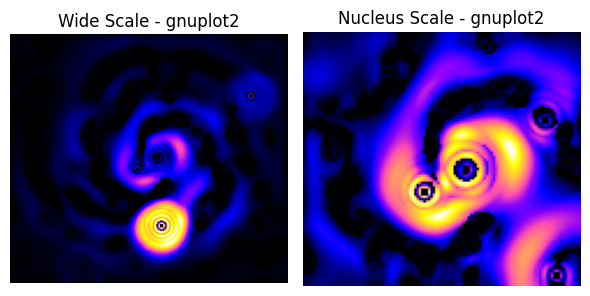

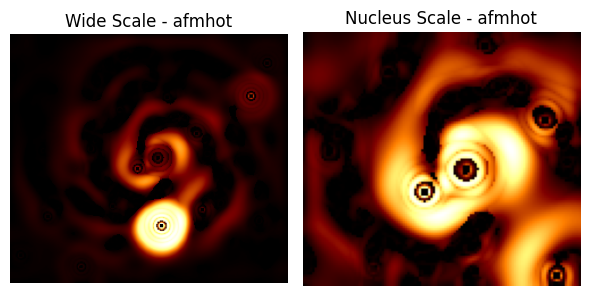

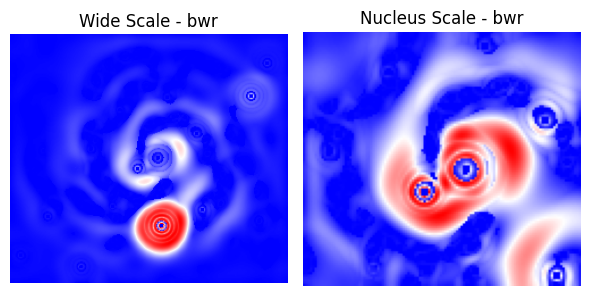

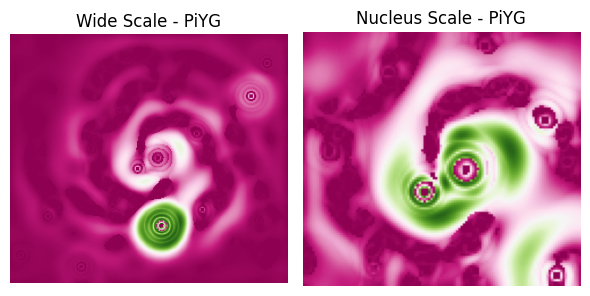

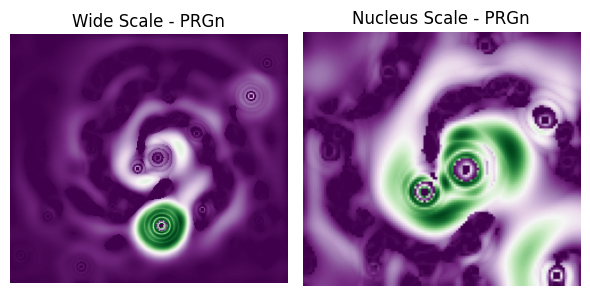

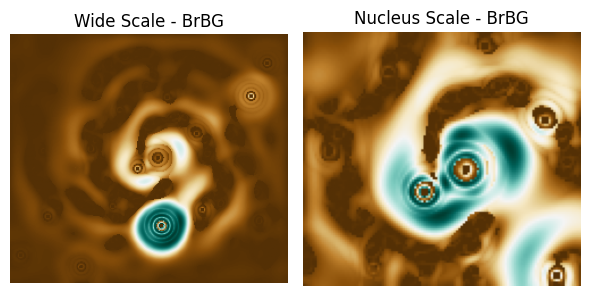

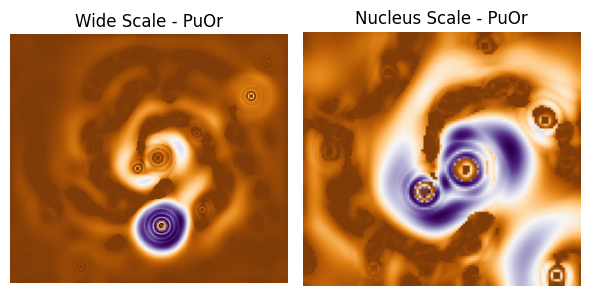

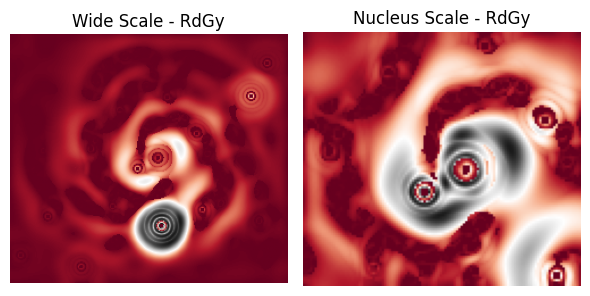

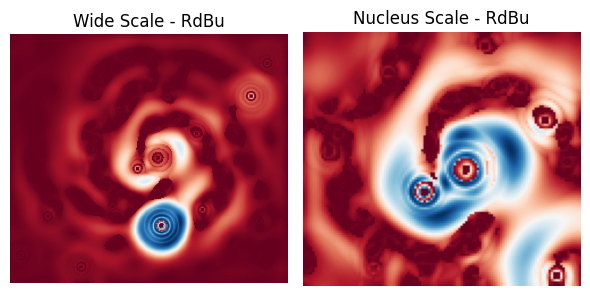

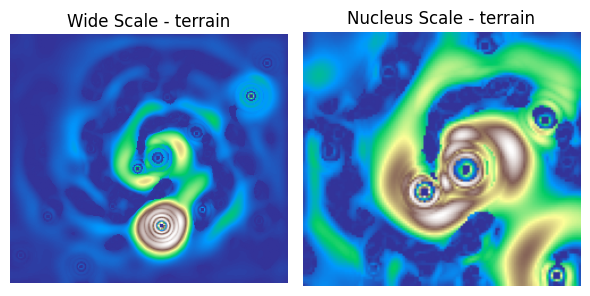

In [93]:
# Use the plotting_NGC3184 to plot green data unit (with meijering filter)
plotting_NGC3184((mei_w_gband, mei_n_gband), SPECTRAL_LIST)

### Step 5: Conclusions

* What can you comment on the barred structure?
* Is the center of the galaxy, more like ringed spiral?
* Are the galactic arms tightly packed or have gaps?
* Can you confirm about the Morphological Classification of NGC3184:- SAB(rs)cd
* Can you comment on anything other than the above conclusions?

In [ ]:
# 1) It is unbarred galaxy (SA)
# 2) It is having spirals starting from the central buldge (s)
# 3) The spiral arms are far away and not that tightly packed (c)
# Final Morphology Classification of NGC3184 according to me:- SA(s)c